# 02 - phase 1: locating a single leak

**task:** one scene has exactly one leak. given the positions of the 6-10 sensors, their readings over 100 timesteps and the wind (speed + direction) over the same 100 timesteps -> predict the (x, y) of the leak.

**loss:** just the euclidean distance between predicted and true position. the site is the `[-1, 1]` box, so a loss of 0.05 means being off by 2.5% of the site width.

**model** (`leaknet/models.py`, `WithDoubleAttention`): the input is a set of sensors (no natural order, different size from scene to scene), observed over time. so the network first looks across the sensors and then across time:

```
per timestep, per sensor: [x, y, concentration, wind direction, wind speed]        [BS, 100, 10, 5]
   -> linear layers -> self attention over the sensors (x2) -> attention pooling    [BS, 100, 20]     one vector per timestep
   -> linear layers -> self attention over the timesteps (x2) -> attention pooling  [BS, 100]         one vector per scene
   -> small mlp -> (x, y)
```

attention blocks are handwritten (single head, `leaknet/attention.py`). the first attempt was to just flatten everything into one 3200-d vector and pass it to an mlp (`FirstDumbMLP`). that one is the baseline here, trained with identical settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from leaknet import plotting, simulation
from leaknet.data import load_scenes
from leaknet.train import EXPERIMENTS, load_run, predict, train_valid_split

RESULTS = "../results"
device = "cuda:0" if torch.cuda.is_available() else "cpu"

model, history = load_run("single_leak", RESULTS)
mlp, history_mlp = load_run("mlp_baseline", RESULTS)

for name, net in [("double attention", model), ("flat mlp", mlp)]:
    print(f"{name:17s}: {sum(p.numel() for p in net.parameters()):9,d} parameters")

double attention :   133,314 parameters
flat mlp         : 1,625,652 parameters


## training

both runs come from `uv run scripts/train.py single_leak mlp_baseline`: 20k scenes (16k train / 4k validation), Adam with lr 1e-3, and a batch size that doubles from 32 to 1024 over 63 epochs (`{32: 1, 64: 2, 128: 4, 256: 8, 512: 16, 1024: 32}` epochs). the batch size schedule is my substitute for a learning rate schedule: small noisy batches to get going quickly, large ones to settle.

shaded band = spread of the per-sample losses within a batch (std separately for the samples above and below the batch mean, because the distribution is very lopsided).

double attention: best validation loss 0.0476   (2648 samples/s, 6.3 min)
flat mlp:         best validation loss 0.4126


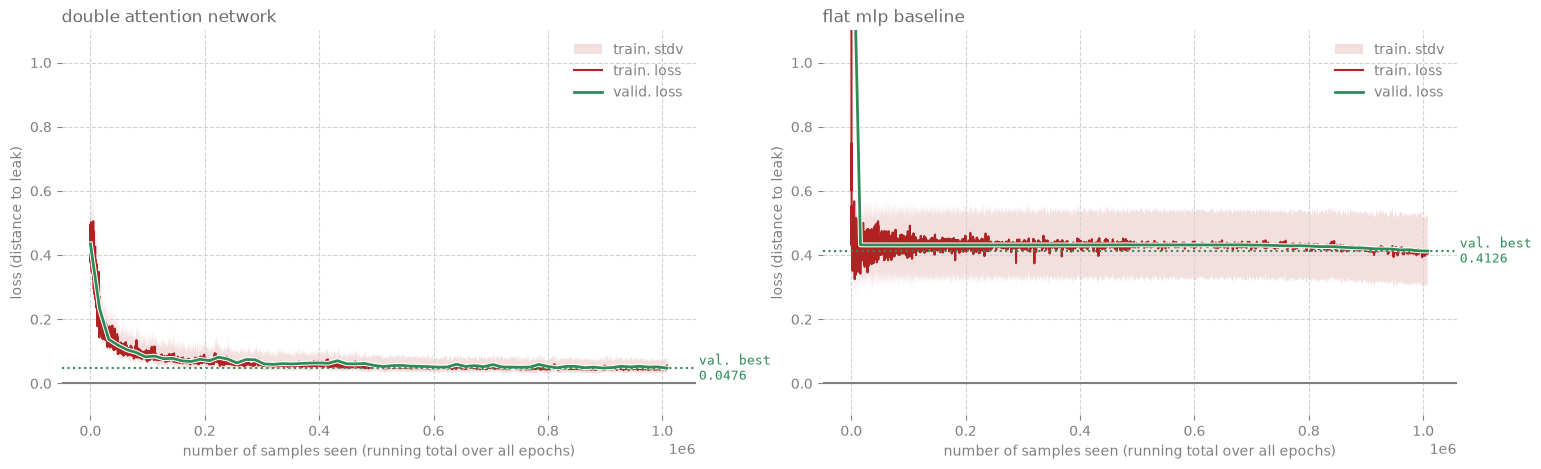

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
plotting.plot_history(history, ax=axes[0], title="double attention network")
plotting.plot_history(history_mlp, ax=axes[1], title="flat mlp baseline")
fig.savefig("../docs/figures/single_leak_training.png", dpi=110, bbox_inches="tight")

print(f"double attention: best validation loss {history['valid_best']:.4f}   ({history['samples_per_second']:.0f} samples/s, {history['train_time_s'] / 60:.1f} min)")
print(f"flat mlp:         best validation loss {history_mlp['valid_best']:.4f}")

both start at about 0.43 = mean distance of a leak to the center of the site. so the first thing any model learns is to predict the center. the attention network leaves that plateau after a few thousand scenes and ends at **0.048**. the flat mlp never leaves it, even though it has 12 times as many parameters! it sees the same numbers, but as one long vector where the meaning of every entry depends on the sensor order and the timestep.

to train interactively there is a live version of this plot (plotly widget, updates after every batch):

```python
from leaknet.plotting import TrainingPlotter
from leaknet.train import run_experiment

plotter = TrainingPlotter(n_epochs=63, l_dataset=16000)
model, history = run_experiment("single_leak", data_dir="../data", plotter=plotter)
```

looks like this, here for two other runs of the same model on a different draw of the dataset. they land in the same place:

| with batch size scheduling (best val. 0.0501) | with standard deviation bands (best val. 0.0468) |
|---|---|
| ![](../docs/screenshots/with_bs_scheduling.png) | ![](../docs/screenshots/with_10e-6.png) |

## how good is it actually?

validation scenes are recovered by redoing the split with the seed of the run.

In [3]:
config = EXPERIMENTS["single_leak"]
data = load_scenes(f"../data/{config['data_file']}")
_, ds_val = train_valid_split(data, config["train_fraction"], seed=history["seed"])
valid = [ds_val[i] for i in range(len(ds_val))]

true = np.array([el["pos_leaks"][0] for el in valid])
pred = predict(model, valid, device).numpy()
pred_mlp = predict(mlp, valid, device).numpy()
error = np.linalg.norm(pred - true, axis=1)
error_mlp = np.linalg.norm(pred_mlp - true, axis=1)

train_leaks = np.array([el["pos_leaks"][0] for el in data[:2000]])
print(f"validation scenes: {len(valid)}")
print(f"always predict the center (0, 0):  mean {np.linalg.norm(true, axis=1).mean():.4f}")
print(f"flat mlp:                          mean {error_mlp.mean():.4f} | median {np.median(error_mlp):.4f}")
print(f"double attention:                  mean {error.mean():.4f} | median {np.median(error):.4f} | 90% below {np.quantile(error, 0.9):.4f} | max {error.max():.3f}")

validation scenes: 4000
always predict the center (0, 0):  mean 0.4316
flat mlp:                          mean 0.4126 | median 0.4020
double attention:                  mean 0.0476 | median 0.0406 | 90% below 0.0863 | max 0.413


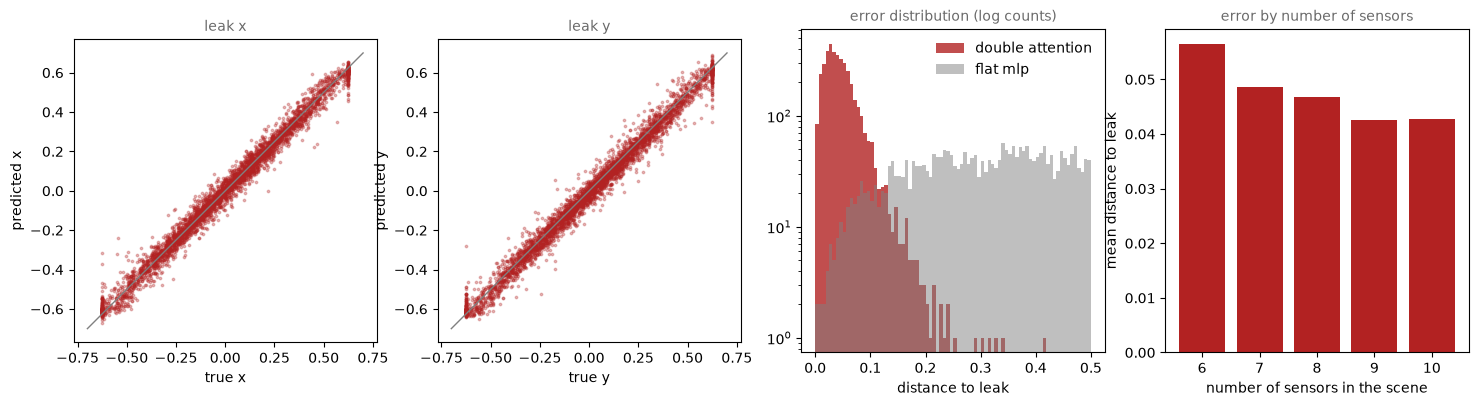

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))

for ax, dim, name in zip(axes, (0, 1), ("x", "y")):
    ax.scatter(true[:, dim], pred[:, dim], s=3, color="firebrick", alpha=0.3)
    ax.plot([-0.7, 0.7], [-0.7, 0.7], color="gray", lw=1)
    ax.set(xlabel=f"true {name}", ylabel=f"predicted {name}", aspect="equal")
    ax.set_title(f"leak {name}", fontsize=10, color="dimgray")

axes[2].hist(error, bins=80, range=(0, 0.5), color="firebrick", alpha=0.8, label="double attention")
axes[2].hist(error_mlp, bins=80, range=(0, 0.5), color="gray", alpha=0.5, label="flat mlp")
axes[2].set(xlabel="distance to leak", yscale="log")
axes[2].set_title("error distribution (log counts)", fontsize=10, color="dimgray")
axes[2].legend(frameon=False)

n_sensors = np.array([int(el["n_sensors"]) for el in valid])
axes[3].bar(range(6, 11), [error[n_sensors == n].mean() for n in range(6, 11)], color="firebrick")
axes[3].set(xlabel="number of sensors in the scene", ylabel="mean distance to leak")
axes[3].set_title("error by number of sensors", fontsize=10, color="dimgray");

- predictions are tight along the diagonal over the whole range, typical error is 0.04, i.e. 2% of the site width.
- the small vertical stacks at ±0.625 are the leaks that sit exactly on the border of the source box (see notebook 01). the model has learned that leaks don't occur outside of it and pulls its predictions inwards.
- more sensors help, but not dramatically: 0.056 with 6 sensors, 0.043 with 9 or 10.
- the error distribution has a thin tail of scenes that are off by 0.2 to 0.4.

### what do the bad scenes look like?

a reading only carries information when it's not zero, i.e. while the sensor is inside a plume. so one guess: the hard scenes are simply the ones where the sensors barely see anything.

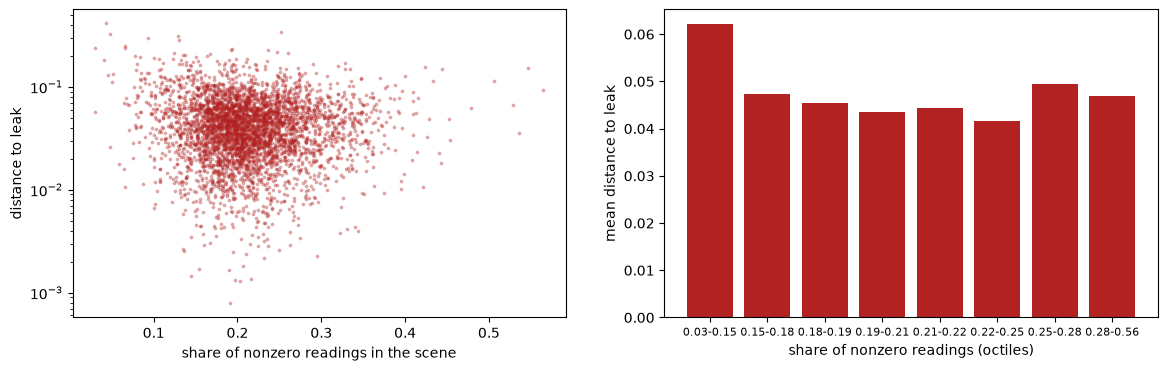

In [5]:
# share of (real) sensor readings in a scene that are above zero
signal = np.array([np.mean(el["con_sensors"][:, : int(el["n_sensors"])] > 0) for el in valid])
edges = np.quantile(signal, np.linspace(0, 1, 9))
bins = np.clip(np.digitize(signal, edges[1:-1]), 0, 7)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(signal, error, s=3, color="firebrick", alpha=0.3)
axes[0].set(xlabel="share of nonzero readings in the scene", ylabel="distance to leak", yscale="log")
axes[1].bar(range(8), [error[bins == i].mean() for i in range(8)], color="firebrick")
axes[1].set_xticks(range(8), [f"{lo:.2f}-{hi:.2f}" for lo, hi in zip(edges[:-1], edges[1:])], fontsize=8)
axes[1].set(xlabel="share of nonzero readings (octiles)", ylabel="mean distance to leak");

only partly true. the eighth of the scenes with the fewest nonzero readings is clearly worse (0.062), but above that the amount of signal makes no difference. so it's not just about how much the sensors see. the individual scenes are more telling:

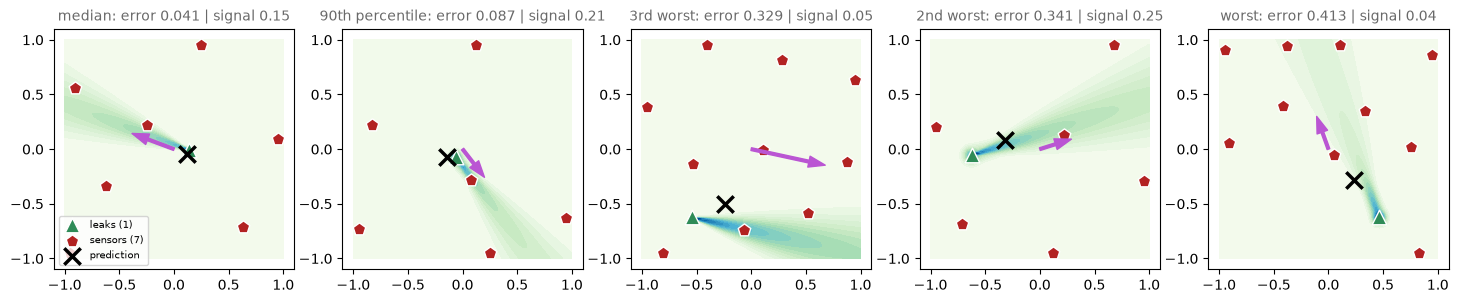

In [6]:
order = np.argsort(error)
picks = [order[len(order) // 2], order[int(len(order) * 0.9)], order[-3], order[-2], order[-1]]
labels = ["median", "90th percentile", "3rd worst", "2nd worst", "worst"]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.9))
for ax, idx, label in zip(axes, picks, labels):
    # show the timestep where the sensors see the most
    t = int(np.argmax(valid[idx]["con_sensors"].clip(0).sum(axis=1)))
    plotting.plot_scene(valid[idx], t=t, ax=ax, show_sources=False, title=f"{label}: error {error[idx]:.3f} | signal {signal[idx]:.2f}")
    ax.scatter(*pred[idx], s=140, marker="x", color="black", lw=2.5, label="prediction", zorder=4)
axes[0].legend(loc="lower left", fontsize=7)
fig.savefig("../docs/figures/single_leak_failures.png", dpi=110, bbox_inches="tight")

(each scene is shown at the timestep where the sensors see the most)

in the worst scenes the leak sits at the border of the source box and only one or two sensors are ever inside the plume. and the prediction is not just somewhere: it lies **on the plume axis**, displaced along the wind! across the wind the leak is pinned down well by which sensors see something and which don't. how far upwind it is has to be read from the concentration level alone, and that is confounded with the unknown leak rate. this is exactly the asymmetry that the "wind covariance" from notebook 01 is meant to describe, the model just has no way to express it with a point prediction.

## unseen sensor layouts

all 20k scenes of the dataset share the same 50 sensor layouts. so the validation scenes above have new leaks and new wind, but sensor layouts that the model has seen hundreds of times -> the validation loss doesn't say whether the model works on a new site. here are 500 fresh scenes with completely new layouts:

double attention, known layouts:  mean 0.0476 | median 0.0406
double attention, new layouts:    mean 0.0535 | median 0.0444
flat mlp, new layouts:            mean 0.4219
always predict the center:        mean 0.4242


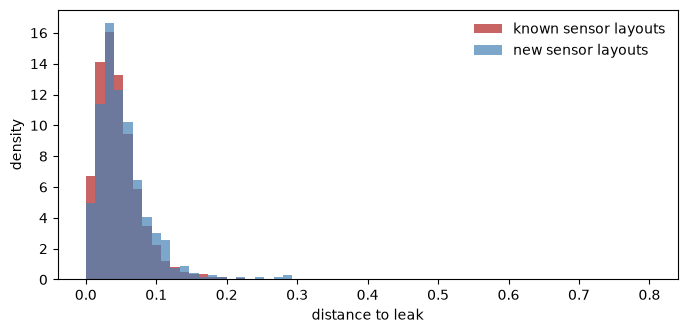

In [7]:
fresh = simulation.generate_collection(n_samples=500, seed=1234, progress=False)

true_fresh = np.array([el["pos_leaks"][0] for el in fresh])
error_fresh = np.linalg.norm(predict(model, fresh, device).numpy() - true_fresh, axis=1)
error_fresh_mlp = np.linalg.norm(predict(mlp, fresh, device).numpy() - true_fresh, axis=1)

print(f"double attention, known layouts:  mean {error.mean():.4f} | median {np.median(error):.4f}")
print(f"double attention, new layouts:    mean {error_fresh.mean():.4f} | median {np.median(error_fresh):.4f}")
print(f"flat mlp, new layouts:            mean {error_fresh_mlp.mean():.4f}")
print(f"always predict the center:        mean {np.linalg.norm(true_fresh, axis=1).mean():.4f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(error, bins=60, range=(0, 0.8), density=True, color="firebrick", alpha=0.7, label="known sensor layouts")
ax.hist(error_fresh, bins=60, range=(0, 0.8), density=True, color="steelblue", alpha=0.7, label="new sensor layouts")
ax.set(xlabel="distance to leak", ylabel="density")
ax.legend(frameon=False);

error goes from 0.048 to 0.054. so the network did **not** just memorize the 50 layouts, it actually reads the sensor positions as inputs and works on sites it has never seen. I expected this to look worse. (the flat mlp is as bad as before, there was nothing to lose haha)

## takeaways

- the double attention network locates a single leak to within about 2-3% of the site width, on known and on new sensor layouts. treating the sensors as a set and the timesteps as a set of observations is what makes the difference: the mlp on the flattened input learns nothing beyond "predict the center".
- the result is stable across runs and dataset draws (0.047 - 0.050).
- the remaining error is not noise in all directions, it's mostly along the wind axis in scenes with little information. natural next step: predict a distribution (e.g. a gaussian per leak) instead of a point.
- all of this is on a memoryless, noise-free toy plume. the README has a list of limitations of the data and the model.